# Higgs check: attention radius sweep

The new knob: message passing plus softmax attention **restricted to nodes within k hops**. k = 0 is pure message
passing (no attention), k = ∞ is attention over the whole subgraph; α is fixed at 0.5 with affine-free branch norms.
k ∈ {0, 1, 2, 3, 4, ∞} plus the `mlp` and `gcn` baselines (`configs/sweeps/higgs_radius.yaml`). A larger k adds
shortcuts past bottlenecks (less over-squashing) but puts more nodes in each softmax (more dilution). Note the
follow graph's effective diameter is about 3.7 hops, so k = 3–4 is already close to ∞ here.

Both targets are run: **`active_after`** (all users) and **`activate_passive`** (the same label, supervised only
on users with no RT/MT/RE activity before the cutoff, so the signal has to come from neighbours). Each variant
runs on **3 split seeds × 2 model seeds**. Changes from the first Higgs sweep: 500-node subgraphs
(~10 test subgraphs instead of 3), a degree-normalised GCN local branch instead of GINE, and exact softmax
attention. **Use a GPU runtime.** Runs take about a minute each.

- **Resume.** After a disconnect, rerun every cell from the top, then the sweep cell: finished runs are skipped.
- **Halo.** `HALO` in the settings cell adds context-only nodes around each subgraph. Leave it at 0 for the first
  pass; with 1, subgraphs can grow several-fold on this dense graph (check the sizes printed in step 10).
- This notebook and the other Higgs-check notebook write to different `exp_name`s and can run in parallel.


## 1. Settings (edit)

`BRANCH` defaults to `main`; set it to another branch to run that code instead.

In [1]:
# EDIT: settings for this notebook
BRANCH = 'social-pipeline'          # git branch to run; change it to test a feature branch
USE_TOKEN = False        # True if the repo is private (needs the GITHUB_TOKEN Colab secret, see step 3)
DRIVE = '/content/drive/MyDrive/Thesis/gnn_mech'
DATA_ROOT = f'{DRIVE}/data'    # downloads and processed caches (kept on Drive, reused by every session)
OUT_DIR = f'{DRIVE}/runs'      # run folders (kept on Drive so runs resume after a disconnect)
LOCAL_DATA = '/content/data'   # fast local copy of the dataset used during training
DATASET = 'higgs-follow'
HALO = 0                 # EDIT: 1 adds 1-hop context-only nodes to every subgraph (larger, slower)
EXTRA = f'data.halo_hops={HALO}' if HALO else ''

## 2. Check the GPU (Runtime > Change runtime type > T4 GPU)

In [2]:
!nvidia-smi

Tue Nov  3 18:19:22 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   53C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 3. Mount Google Drive

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 4. Get the code

Clones the repo at `BRANCH`, or pulls if it is already there. If the repo is private, create a GitHub
personal access token (read access to the repo is enough), store it as a Colab secret named
`GITHUB_TOKEN` (key icon in the left sidebar) and set `USE_TOKEN = True` in step 1. Never paste the
token into the notebook itself.

In [4]:
import os, subprocess

REPO_DIR = '/content/message-passing-in-gnns'
url = 'https://github.com/djdhawal/message-passing-in-gnns.git'
if USE_TOKEN:
    from google.colab import userdata
    url = f"https://{userdata.get('GITHUB_TOKEN')}@github.com/djdhawal/message-passing-in-gnns.git"

if os.path.isdir(os.path.join(REPO_DIR, '.git')):
    subprocess.run(['git', '-C', REPO_DIR, 'fetch', 'origin', BRANCH], check=True)
    subprocess.run(['git', '-C', REPO_DIR, 'checkout', BRANCH], check=True)
    subprocess.run(['git', '-C', REPO_DIR, 'pull', 'origin', BRANCH], check=True)
else:
    subprocess.run(['git', 'clone', '--branch', BRANCH, url, REPO_DIR], check=True)
%cd {REPO_DIR}
!git log -1 --oneline

/content/message-passing-in-gnns
7664bda (HEAD -> social-pipeline, origin/social-pipeline) run on collab


## 5. Install

In [5]:
!pip install -q torch_geometric
!pip install -q -e .

  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for gnn_mech (pyproject.toml) ... done


## 6. Folders on Drive

In [6]:
os.makedirs(DATA_ROOT, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(LOCAL_DATA, exist_ok=True)
print('data on Drive:', DATA_ROOT)
print('runs on Drive:', OUT_DIR)

data on Drive: /content/drive/MyDrive/Thesis/gnn_mech/data
runs on Drive: /content/drive/MyDrive/Thesis/gnn_mech/runs


### Sweep file

In [7]:
SWEEP = 'configs/sweeps/higgs_radius.yaml'
print('sweep:', SWEEP, '' if os.path.exists(SWEEP) else '(MISSING: check BRANCH)')

sweep: configs/sweeps/higgs_radius.yaml 


## 7. Data helpers

`find_source_dir` finds the dataset's folder under `<root>/social/`. `sync` copies only files that are
missing or newer (rsync). Nothing to edit here.

In [8]:
import shutil
from pathlib import Path


def _source_candidates(name):
    # Folder names under <root>/social/ that may hold `name`; gnn_mech.social.sources decides when it can.
    cands = []
    try:
        from gnn_mech.social import sources
        for attr in ('source_of', 'source_name', 'source_for'):
            fn = getattr(sources, attr, None)
            if callable(fn):
                try:
                    cands.append(str(fn(name)))
                except Exception:
                    pass
        for attr in ('SOURCES', 'SOURCE_OF', 'DATASET_SOURCE', 'DATASETS'):
            table = getattr(sources, attr, None)
            if isinstance(table, dict) and name in table:
                v = table[name]
                if not isinstance(v, str):
                    v = v.get('source') if isinstance(v, dict) else getattr(v, 'source', None)
                if v:
                    cands.append(str(v))
    except Exception:
        pass
    cands.append(name)
    if name.startswith('twitch-') and name != 'twitch-gamers':
        cands += ['musae', 'twitch', 'twitch-musae', 'musae-twitch']
    if name.startswith('higgs-'):
        cands += ['higgs', 'higgs-twitter']
    if name.startswith('reddit-'):
        cands += ['reddit', 'reddit-hyperlinks', 'soc-redditHyperlinks']
    return list(dict.fromkeys(cands))


def find_source_dir(name, root, fetched=None):
    # Name of the folder <root>/social/<source>/ that holds `name`, or None if it does not exist yet.
    social = Path(root) / 'social'
    if isinstance(fetched, (str, os.PathLike)):
        try:
            rel = Path(fetched).resolve().relative_to(social.resolve())
            if rel.parts:
                return rel.parts[0]
        except Exception:
            pass
    for c in _source_candidates(name):
        if (social / c).is_dir():
            return c
    return None


def sync(src, dst):
    # Copy files that are missing or newer in src into dst; never deletes anything.
    os.makedirs(dst, exist_ok=True)
    if shutil.which('rsync'):
        subprocess.run(['rsync', '-a', '--update', f'{src}/', f'{dst}/'], check=True)
    else:
        shutil.copytree(src, dst, dirs_exist_ok=True)

## 8. Download the dataset into Drive (once)

`gnn_mech.social.sources.fetch` downloads and parses the raw files into `DATA_ROOT/social/<source>/` and
skips files that already exist, so later sessions reuse them. If it fails, the run downloads the data
itself on first use.

In [9]:
fetched = None
try:
    from gnn_mech.social import sources
    fetched = sources.fetch(DATASET, root=DATA_ROOT)
except Exception as e:
    print(f'[warn] fetch({DATASET!r}) failed: {e!r}')
SOURCE = find_source_dir(DATASET, DATA_ROOT, fetched)
print('source folder on Drive:', SOURCE)

source folder on Drive: higgs


## 9. Copy the dataset to local disk

Training reads from `LOCAL_DATA` (much faster than Drive). Only missing or newer files are copied.
Run outputs still go to `OUT_DIR` on Drive.

In [10]:
if SOURCE:
    sync(f'{DATA_ROOT}/social/{SOURCE}', f'{LOCAL_DATA}/social/{SOURCE}')
    RUN_DATA = LOCAL_DATA
else:
    print('[warn] no dataset folder on Drive yet: this session reads and writes data on Drive directly')
    RUN_DATA = DATA_ROOT
COMMON = f'out_dir={OUT_DIR} data.root={RUN_DATA}'
print(COMMON)

out_dir=/content/drive/MyDrive/Thesis/gnn_mech/runs data.root=/content/data


In [11]:
!du -sh {RUN_DATA}/social/* 2>/dev/null || echo 'nothing local yet'

133M	/content/data/social/higgs


## 10. Build the subgraph cache (first session only) and save it to Drive

Loads every data config used by the sweep once. The first time, this partitions the graph and writes
`social/<source>/processed/<hash>.pt`; later sessions find it and skip the work. New files are then copied
back to Drive so the next session reuses them.

In [12]:
import gc, json
from gnn_mech.data import load_dataset

from gnn_mech.sweep import load_sweep
try:
    DATA_CFGS = [(r.name, r.cfg) for r in load_sweep(SWEEP, [f'out_dir={OUT_DIR}', f'data.root={RUN_DATA}'] + ([EXTRA] if EXTRA else []))[0]]
except Exception as e:
    DATA_CFGS = []
    print(f'[warn] could not read {SWEEP}: {e!r}')
seen = set()
for label, c in DATA_CFGS:
    d = c.to_dict()['data']
    d.pop('root', None)
    key = json.dumps(d, sort_keys=True, default=str)
    if key in seen:
        continue
    seen.add(key)
    try:
        tr, va, te, info = load_dataset(c.data)
        print(f'{label}: {len(tr)} / {len(va)} / {len(te)} subgraphs (train / val / test), '
              f'task {info.task}, feat_dim {getattr(info, "feat_dim", "?")}, '
              f'median subgraph size {int(sorted(g.num_nodes for g in tr)[len(tr) // 2])}')
        del tr, va, te
    except Exception as e:
        print(f'[warn] could not prepare data for {label}: {e!r} (the run will try again)')
gc.collect()

if SOURCE is None:
    SOURCE = find_source_dir(DATASET, RUN_DATA)
if RUN_DATA != DATA_ROOT and SOURCE:
    sync(f'{RUN_DATA}/social/{SOURCE}', f'{DATA_ROOT}/social/{SOURCE}')
    print('cache saved to Drive:', f'{DATA_ROOT}/social/{SOURCE}')

active_after/split0/radius0: 49 / 11 / 11 subgraphs (train / val / test), task binary, feat_dim 11, median subgraph size 502
active_after/split1/radius0: 49 / 11 / 11 subgraphs (train / val / test), task binary, feat_dim 11, median subgraph size 502
active_after/split2/radius0: 49 / 11 / 11 subgraphs (train / val / test), task binary, feat_dim 11, median subgraph size 502
activate_passive/split0/radius0: 49 / 11 / 11 subgraphs (train / val / test), task binary, feat_dim 11, median subgraph size 502
activate_passive/split1/radius0: 49 / 11 / 11 subgraphs (train / val / test), task binary, feat_dim 11, median subgraph size 502
activate_passive/split2/radius0: 49 / 11 / 11 subgraphs (train / val / test), task binary, feat_dim 11, median subgraph size 502
cache saved to Drive: /content/drive/MyDrive/Thesis/gnn_mech/data/social/higgs


## 11. Dry run: the run list, each run's status and the estimated remaining hours

In [13]:
!python -m gnn_mech.sweep {SWEEP} --dry-run {COMMON} {EXTRA}

[ 0] todo    active_after/split0/radius0 seed 0  higgs_radius/a2b5d6f4f5  ~1 min  exp_name=higgs_radius data.target=active_after data.split_seed=0 model.alpha=0.0 out_dir=/content/drive/MyDrive/Thesis/gnn_mech/runs data.root=/content/data
[ 1] todo    active_after/split0/radius0 seed 1  higgs_radius/a2b5d6f4f5  ~1 min  exp_name=higgs_radius data.target=active_after data.split_seed=0 model.alpha=0.0 out_dir=/content/drive/MyDrive/Thesis/gnn_mech/runs data.root=/content/data
[ 2] todo    active_after/split0/radius1 seed 0  higgs_radius/9f55de3eb9  ~1 min  exp_name=higgs_radius data.target=active_after data.split_seed=0 model.alpha=0.5 model.attn=radius model.attn_radius=1 out_dir=/content/drive/MyDrive/Thesis/gnn_mech/runs data.root=/content/data
[ 3] todo    active_after/split0/radius1 seed 1  higgs_radius/9f55de3eb9  ~1 min  exp_name=higgs_radius data.target=active_after data.split_seed=0 model.alpha=0.5 model.attn=radius model.attn_radius=1 out_dir=/content/drive/MyDrive/Thesis/gnn_me

## 12. Run the sweep (rerun this cell after a disconnect to resume)

In [14]:
!python -m gnn_mech.sweep {SWEEP} {COMMON} {EXTRA}

[ 0] todo    active_after/split0/radius0 seed 0  higgs_radius/a2b5d6f4f5  ~1 min  exp_name=higgs_radius data.target=active_after data.split_seed=0 model.alpha=0.0 out_dir=/content/drive/MyDrive/Thesis/gnn_mech/runs data.root=/content/data
[ 1] todo    active_after/split0/radius0 seed 1  higgs_radius/a2b5d6f4f5  ~1 min  exp_name=higgs_radius data.target=active_after data.split_seed=0 model.alpha=0.0 out_dir=/content/drive/MyDrive/Thesis/gnn_mech/runs data.root=/content/data
[ 2] todo    active_after/split0/radius1 seed 0  higgs_radius/9f55de3eb9  ~1 min  exp_name=higgs_radius data.target=active_after data.split_seed=0 model.alpha=0.5 model.attn=radius model.attn_radius=1 out_dir=/content/drive/MyDrive/Thesis/gnn_mech/runs data.root=/content/data
[ 3] todo    active_after/split0/radius1 seed 1  higgs_radius/9f55de3eb9  ~1 min  exp_name=higgs_radius data.target=active_after data.split_seed=0 model.alpha=0.5 model.attn=radius model.attn_radius=1 out_dir=/content/drive/MyDrive/Thesis/gnn_me

### Save any new data files back to Drive

In [15]:
if RUN_DATA != DATA_ROOT:
    SOURCE = SOURCE or find_source_dir(DATASET, RUN_DATA)
    if SOURCE:
        sync(f'{RUN_DATA}/social/{SOURCE}', f'{DATA_ROOT}/social/{SOURCE}')
        print('synced to Drive')

synced to Drive


## 13. Results: test metric vs attention radius per target (mean ± std over split and model seeds)

experiments: ['higgs_radius']


,target,metric,variant,n,test (mean ± std),val_mean,minutes
1,activate_passive,auroc,k=0,6,0.6601 ± 0.0106,0.687392,0.541760
2,activate_passive,auroc,k=1,6,0.6633 ± 0.0062,0.680687,1.036411
3,activate_passive,auroc,k=2,6,0.6539 ± 0.0080,0.682081,1.177426
4,activate_passive,auroc,k=3,6,0.6529 ± 0.0100,0.677520,1.203448
5,activate_passive,auroc,k=4,6,0.6527 ± 0.0138,0.677932,1.416890
6,activate_passive,auroc,k=inf,6,0.6536 ± 0.0114,0.676201,1.140729
0,activate_passive,auroc,gcn,6,0.6655 ± 0.0108,0.682372,0.470768
7,activate_passive,auroc,mlp,6,0.6635 ± 0.0090,0.677478,0.326914
9,active_after,auroc,k=0,6,0.7040 ± 0.0111,0.691694,0.745506
10,active_after,auroc,k=1,6,0.7050 ± 0.0094,0.694663,1.442952


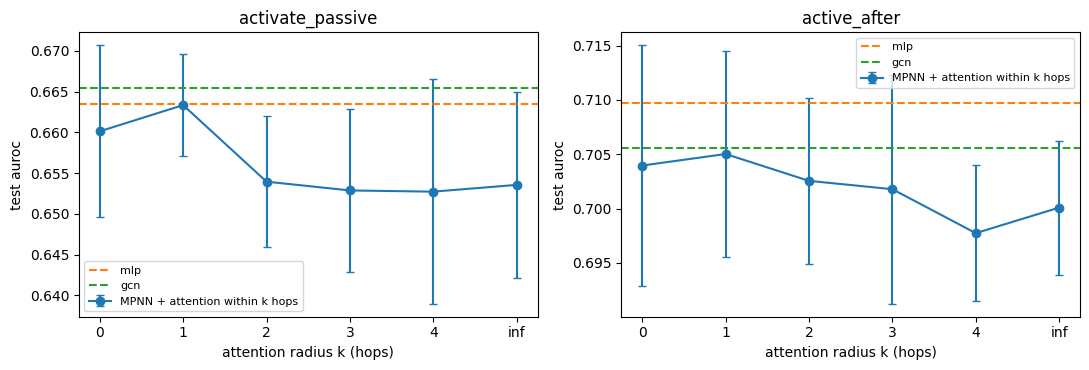

In [16]:
import json, os
import numpy as np
import pandas as pd

PRIMARY = ('auroc', 'acc', 'r2', 'ap', 'mae', 'rmse')   # first one present is the headline metric
BASELINES = ('mlp', 'gcn')


def read_json(path):
    try:
        with open(path) as f:
            return json.load(f)
    except Exception:
        return None


def primary_metric(split):
    keys = [k for k, v in (split or {}).items() if k != 'loss' and isinstance(v, (int, float))]
    for k in PRIMARY:
        if k in keys:
            return k
    return keys[0] if keys else None

def collect(out_dir, exps=None):
    # One row per finished run (config.json + metrics.json); unreadable or unfinished runs are skipped.
    rows = []
    root = Path(out_dir)
    if not root.is_dir():
        return pd.DataFrame()
    for cfg_path in root.glob('*/*/seed*/config.json'):
        run = cfg_path.parent
        exp = run.parent.parent.name
        if exps is not None and exp not in exps:
            continue
        cfg, m = read_json(cfg_path), read_json(run / 'metrics.json')
        if not cfg or not m or not isinstance(m.get('test'), dict):
            continue
        model, data = cfg.get('model', {}), cfg.get('data', {})
        metric = primary_metric(m['test'])
        row = {'exp': exp, 'hash': run.parent.name, 'dataset': data.get('name'), 'target': data.get('target', ''),
               'arch': model.get('arch'), 'attn': model.get('attn', 'softmax'), 'alpha': model.get('alpha'),
               'seed': cfg.get('seed'), 'metric': metric,
               'test': m['test'].get(metric), 'val': (m.get('val') or {}).get(metric),
               'best_epoch': m.get('best_epoch'), 'epochs_run': m.get('epochs_run'),
               'hours': (m.get('seconds') or 0) / 3600, 'n_params': m.get('n_params'), 'path': str(run)}
        row.update({f'test_{k}': v for k, v in m['test'].items() if isinstance(v, (int, float))})
        rows.append(row)
    return pd.DataFrame(rows)



def add_cfg_fields(df):
    # split seed, radius and branch-affine are not in collect(); read them from each run's config.json
    extra = []
    for p in df['path']:
        cfg = read_json(Path(p) / 'config.json') or {}
        m, d = cfg.get('model', {}), cfg.get('data', {})
        extra.append({'split_seed': d.get('split_seed', 0), 'radius': m.get('attn_radius', -1),
                      'halo': d.get('halo_hops', 0), 'local': m.get('local')})
    return pd.concat([df.reset_index(drop=True), pd.DataFrame(extra)], axis=1)


def summarize(df, keys):
    # mean +- std over model seeds x split seeds; n = number of runs
    g = df.groupby(keys, dropna=False)
    out = g.agg(n=('test', 'size'), mean=('test', 'mean'), std=('test', 'std'),
                val_mean=('val', 'mean'), minutes=('hours', lambda h: 60 * h.sum())).reset_index()
    out['std'] = out['std'].fillna(0.0)
    out['test (mean ± std)'] = [f'{a:.4f} ± {b:.4f}' for a, b in zip(out['mean'], out['std'])]
    return out

from pathlib import Path
import matplotlib.pyplot as plt
from gnn_mech.sweep import load_sweep

EXPS = sorted({r.cfg.exp_name for r in load_sweep(SWEEP, [f'out_dir={OUT_DIR}'])[0]})
print('experiments:', EXPS)
runs_df = collect(OUT_DIR, EXPS)
if runs_df.empty:
    print('no finished runs yet')
else:
    runs_df = add_cfg_fields(runs_df)
    RESULTS = f'{DRIVE}/results/{EXPS[0]}'
    os.makedirs(RESULTS, exist_ok=True)
    runs_df.to_csv(f'{RESULTS}/runs.csv', index=False)
    def variant(r):
        if r['arch'] != 'hybrid':
            return r['arch']
        if r['alpha'] == 0:
            return 'k=0'
        return 'k=inf' if r['attn'] == 'softmax' or r['radius'] < 0 else f"k={int(r['radius'])}"
    runs_df['variant'] = runs_df.apply(variant, axis=1)
    order = {'k=0': 0, 'k=1': 1, 'k=2': 2, 'k=3': 3, 'k=4': 4, 'k=inf': 5}
    runs_df['k_pos'] = runs_df['variant'].map(order)
    table = summarize(runs_df, ['target', 'metric', 'variant', 'arch', 'k_pos'])
    table.to_csv(f'{RESULTS}/summary.csv', index=False)
    display(table.sort_values(['target', 'k_pos'])[['target', 'metric', 'variant', 'n', 'test (mean ± std)', 'val_mean', 'minutes']])

    targets = sorted(table['target'].unique())
    fig, axes = plt.subplots(1, len(targets), figsize=(5.5 * len(targets), 3.8), squeeze=False)
    for ax, t in zip(axes[0], targets):
        sub = table[table['target'] == t]
        hyb = sub[sub['arch'] == 'hybrid'].sort_values('k_pos')
        ax.errorbar(hyb['k_pos'], hyb['mean'], yerr=hyb['std'], marker='o', capsize=3, label='MPNN + attention within k hops')
        for i, b in enumerate(('mlp', 'gcn')):
            r = sub[sub['arch'] == b]
            if len(r):
                ax.axhline(r['mean'].iloc[0], ls='--', color=f'C{i + 1}', label=b)
        ax.set_xticks(range(6), ['0', '1', '2', '3', '4', 'inf'])
        ax.set(title=t, xlabel='attention radius k (hops)', ylabel=f"test {sub['metric'].iloc[0]}")
        ax.legend(fontsize=8)
    fig.tight_layout(); fig.savefig(f'{RESULTS}/radius_curve.png', dpi=150); plt.show()
